In [1]:
%pip install reservoirpy

#Referencia para la instalación:
#Nathan Trouvain, Luca Pedrelli, Thanh Trung Dinh, Xavier Hinaut. ReservoirPy: an Efficient and User-Friendly Library to Design Echo State Networks. 2020. ⟨hal-02595026⟩ https://hal.inria.fr/hal-02595026

In [2]:
import reservoirpy as rpy
from reservoirpy.nodes import Reservoir
#reservoirpy.hyper para automatizar la busqueda de los mejores parametros
rpy.set_seed(42)
#reservoir = Reservoir()

In [3]:
#PArte 1 : datos simulados
#usando lorenz 96 su ec.diferencial


#solucion por runge kuta 4
import numpy as np
import os

# parte 1: datos simulados con lorenz 96, resuelto con runge kutta 4
#esto para definir
def lorenz96(x, F):
    # dx_j/dt = (x_{j+1} - x_{j-2}) * x_{j-1} - x_j + F
    Q = len(x)
    dx = np.zeros(Q)
    for j in range(Q):
        # indices modulo Q -> frontera periodica
        dx[j] = (x[(j+1) % Q] - x[(j-2) % Q]) * x[(j-1) % Q] - x[j] + F
    return dx

def paso_rk4(x, F, dt):
    k1 = lorenz96(x, F)
    k2 = lorenz96(x + 0.5*dt*k1, F)
    k3 = lorenz96(x + 0.5*dt*k2, F)
    k4 = lorenz96(x + dt*k3, F)
    return x + (dt/6.0)*(k1 + 2*k2 + 2*k3 + k4)

def generar_datos(Q=36, F=8.0, dt=0.01, pasos_guardados=20000, cada=5, transitorio=5000):
  # condicion inicial: todo en F y una perturbacion  en x_0 pARA QUE SEA CAHOTIIC
    x = F*np.ones(Q)
    x[0] += 0.01

    # descartamos el transitorio (los datos del inicio pues que se ven muy afectados por las condiciones iniciales que deberian ser arbitrarias)
    for i in range(transitorio):
        x = paso_rk4(x, F, dt)

    # filas = tiempo, columnas = variables
    U = np.zeros((pasos_guardados, Q))
    fila = 0
    paso = 0
    while fila < pasos_guardados:
        x = paso_rk4(x, F, dt)
        if paso % cada == 0:      # guardamos 1 de cada 'cada' pasosss
            U[fila] = x
            fila += 1
        paso += 1

    return U

U = generar_datos()
print("Forma de los datos (tiempo, variables):", U.shape)
print("Primeras 2 filas:\n", U[:2])
#crear la super carpeta de los datoos
os.makedirs("datos", exist_ok=True)
np.save("datos/lorenz96.npy", U)
print("Guardado en datos/lorenz96.npy")

Forma de los datos (tiempo, variables): (20000, 36)
Primeras 2 filas:
 [[-0.72552264  2.46472299  2.60883472  5.45255529  1.74731621 -2.37615039
   0.64781479  8.70511315  0.28256157 -3.43517844  2.86822872  6.73450659
   2.5924355   4.30623275  4.48957027 -3.56568276  1.46102138  2.08373188
   8.02555054 -0.7573825  -1.05184529  1.23361959 11.73920185  0.9242563
  -3.12329854  1.65634572  5.60604995 -0.86357717 -2.52971346  0.93004597
   5.80407296  9.27354826 -0.74485182 -7.00972019  0.02183535  8.62157974]
 [ 1.40011479  2.68229973  3.53175745  5.35580666  0.6273682  -2.16005962
   0.16795516  8.71226538 -0.84413049 -2.77153233  1.98131926  7.52128444
   3.47426206  4.00056155  3.32244208 -3.46651724  1.98718824  3.35209442
   7.62759824 -1.61691273 -0.22402033  1.1561396  11.58827876 -1.03969725
  -2.52276129  1.14342417  5.84380594 -1.42154413 -1.726385    0.52277466
   6.29064089  8.01817897 -5.48787493 -4.59429499 -2.98773587  8.13087605]]
Guardado en datos/lorenz96.npy


In [17]:
# ======================================================================
#  ENTRENAMIENTO ESN  —  readout sobre [r ; r^2]  (fiel a Pathak et al.)
# ======================================================================
from reservoirpy.nodes import Reservoir, Ridge
from reservoirpy.observables import nrmse
import matplotlib.pyplot as plt
import numpy as np

# ---------- Datos ----------
U = np.load("datos/lorenz96.npy")        # (20000, 36)
n_train = 15000
U_train = U[:n_train]
U_test  = U[n_train:]

media = U_train.mean(axis=0)
std   = U_train.std(axis=0)
U_train_norm = (U_train - media) / std
U_test_norm  = (U_test  - media) / std

# Entrada con ruido (estabiliza la realimentacion autonoma), objetivo limpio
noise_amp = 0.05
X_train = U_train_norm[:-1] + noise_amp * np.random.default_rng(42).standard_normal(U_train_norm[:-1].shape)
Y_train = U_train_norm[1:]

# ---------- Reservoir ----------
reservoir = Reservoir(
    units=2000,
    lr=0.9,
    sr=0.6,
    input_scaling=0.1,
    input_connectivity=0.1,
    rc_connectivity=0.05,
    seed=42,
)
readout = Ridge(ridge=1.0)              # regularizacion mas fuerte para [r ; r^2]

# ---------- ENTRENAMIENTO: armar [r ; r^2] y entrenar solo la salida ----------
R = reservoir.run(X_train)                       # estados r(t), forma (n, N)
R_feat = np.concatenate([R, R**2], axis=1)       # [r ; r^2]  (cuadrados PUROS, sin cruzados)
print("Dimension de caracteristicas:", R_feat.shape)   # (n, 2N) = (n, 4000)

warmup = 100
readout.fit(R_feat[warmup:], Y_train[warmup:])

# diagnostico: error a UN paso (sin realimentacion)
Y_onestep = readout.run(R_feat)
print(f"NRMSE 1-paso (norm): {nrmse(Y_train, Y_onestep):.4f}")

# ---------- PREDICCION autonoma ----------
reservoir.reset()
step_warmup    = 150
step_prediccion = 300

R_wu = reservoir.run(U_test_norm[:step_warmup])  # sincroniza el estado con datos reales
r_actual = np.asarray(R_wu[-1]).ravel()
u_actual = readout.run(np.concatenate([r_actual, r_actual**2]).reshape(1, -1)).ravel()

predicciones_norm = np.zeros((step_prediccion, U.shape[1]))
predicciones_norm[0] = u_actual

for t in range(1, step_prediccion):
    R_step = reservoir.run(u_actual.reshape(1, -1))      # avanza un paso con su propia prediccion
    r_actual = np.asarray(R_step[-1]).ravel()
    u_actual = readout.run(np.concatenate([r_actual, r_actual**2]).reshape(1, -1)).ravel()
    predicciones_norm[t] = u_actual

Y_pred = predicciones_norm * std + media          # desnormalizar para graficar
Y_real = U_test[step_warmup : step_warmup + step_prediccion]

# ======================================================================
#  CRITERIO DE VALIDACION  (tiempo de Lyapunov)
# ======================================================================
dt_datos   = 0.05                    # Δt entre filas (dt=0.01 * cada=5)
lambda_max = 1.67                    # exponente de Lyapunov maximo (Lorenz-96, F=8, N=36)
t_lyapunov = 1.0 / lambda_max        # ≈ 0.599 u.t.

Y_true_norm = U_test_norm[step_warmup : step_warmup + step_prediccion]
err_t = np.sqrt(((predicciones_norm - Y_true_norm)**2).mean(axis=1))

umbral = 0.3
cruce = np.argmax(err_t > umbral) if np.any(err_t > umbral) else step_prediccion
t_valido_ut   = cruce * dt_datos
t_valido_lyap = t_valido_ut / t_lyapunov

print(f"Prediccion valida: {cruce} pasos = {t_valido_ut:.2f} u.t. = {t_valido_lyap:.2f} tiempos de Lyapunov")


Dimension de caracteristicas: (14999, 4000)
NRMSE 1-paso (norm): 0.0083
Prediccion valida: 5 pasos = 0.25 u.t. = 0.42 tiempos de Lyapunov


Error Normalizado: 0.2411


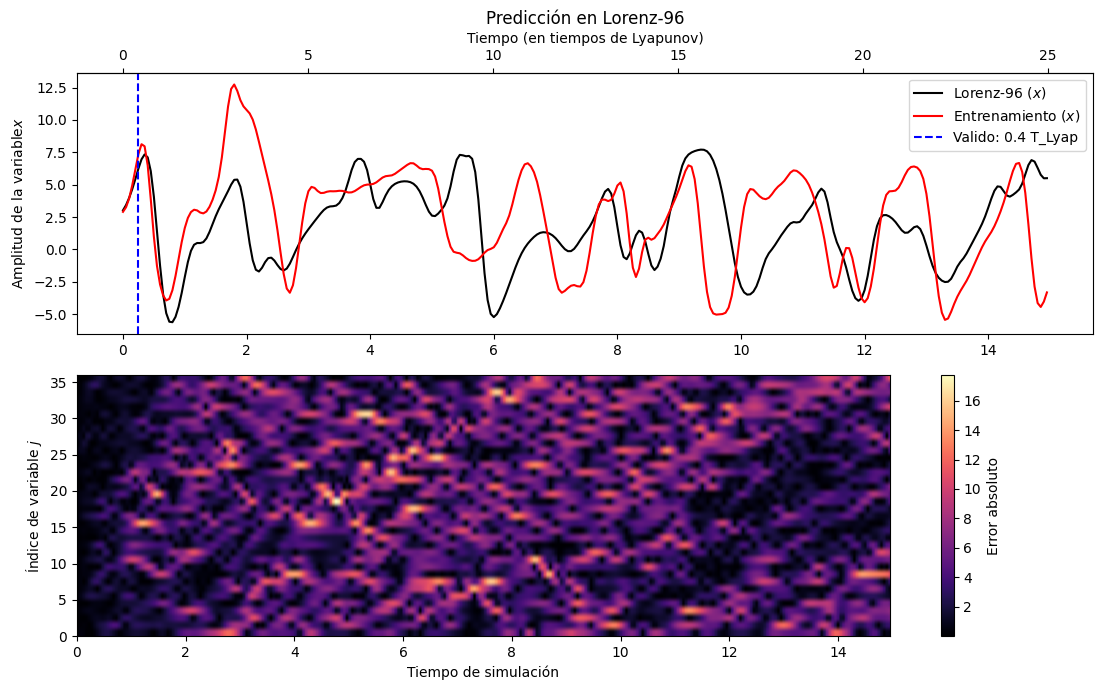

In [19]:
tiempo = np.arange(step_prediccion) * 0.05
fig, axes = plt.subplots(2, 1, figsize=(11, 7))

#Predicción para una variable, puede verse de 0 a 35
axes[0].plot(tiempo, Y_real[:, 11], label="Lorenz-96 ($x$)", color="black")
axes[0].plot(tiempo, Y_pred[:, 11], label="Entrenamiento ($x$)", color="red")
axes[0].set_ylabel("Amplitud de la variable$x$")
axes[0].set_title("Predicción en Lorenz-96")
axes[0].legend()

axes[0].axvline(t_valido_ut, color="blue", ls="--",
                label=f"Valido: {t_valido_lyap:.1f} T_Lyap")
axes[0].legend()   # vuelve a llamarlo para que aparezca la linea azul
secax = axes[0].secondary_xaxis('top',
    functions=(lambda t: t / t_lyapunov, lambda l: l * t_lyapunov))
secax.set_xlabel("Tiempo (en tiempos de Lyapunov)")


print(f"Error Normalizado: {nrmse(Y_real[:], Y_pred[:]):.4f}")
#Error para todas las variables en cada paso de tiempo
error_abs = np.abs(Y_real - Y_pred).T
im = axes[1].imshow(error_abs, aspect="auto", origin="lower",
                    extent=[tiempo[0], tiempo[-1], 0, U.shape[1]], cmap="magma")
axes[1].set_ylabel("Índice de variable $j$")
axes[1].set_xlabel("Tiempo de simulación")
fig.colorbar(im, ax=axes[1], label="Error absoluto")

plt.tight_layout()
plt.savefig("prediccion_lorenz96.png")
plt.show()

In [20]:
# ======================================================================
#  BARRIDO DE HIPERPARAMETROS  (ESN con readout [r ; r^2])
# ======================================================================
from reservoirpy.nodes import Reservoir, Ridge
import numpy as np

dt_datos   = 0.05
lambda_max = 1.67
t_lyapunov = 1.0 / lambda_max
step_warmup, step_prediccion = 150, 300

def evaluar(units, lr, sr, input_scaling, ridge, noise_amp, seed=42):
    rng = np.random.default_rng(seed)
    Xtr = U_train_norm[:-1] + noise_amp * rng.standard_normal(U_train_norm[:-1].shape)
    Ytr = U_train_norm[1:]

    res = Reservoir(units=units, lr=lr, sr=sr, input_scaling=input_scaling,
                    input_connectivity=0.1, rc_connectivity=0.05, seed=seed)
    rd = Ridge(ridge=ridge)

    R = res.run(Xtr)
    Rf = np.concatenate([R, R**2], axis=1)
    rd.fit(Rf[100:], Ytr[100:])

    res.reset()
    R_wu = res.run(U_test_norm[:step_warmup])
    r = np.asarray(R_wu[-1]).ravel()
    u = rd.run(np.concatenate([r, r**2]).reshape(1, -1)).ravel()
    pred = np.zeros((step_prediccion, U.shape[1])); pred[0] = u
    for t in range(1, step_prediccion):
        r = np.asarray(res.run(u.reshape(1, -1))[-1]).ravel()
        u = rd.run(np.concatenate([r, r**2]).reshape(1, -1)).ravel()
        pred[t] = u

    Yt = U_test_norm[step_warmup:step_warmup+step_prediccion]
    err = np.sqrt(((pred - Yt)**2).mean(axis=1))
    cruce = np.argmax(err > 0.3) if np.any(err > 0.3) else step_prediccion
    return cruce * dt_datos / t_lyapunov   # horizonte en tiempos de Lyapunov

# --- barrido sobre los parametros que mas importan ---
resultados = []
for sr in [0.4, 0.8, 1.2]:
    for input_scaling in [0.1, 0.5, 1.0]:
        for ridge in [1e-4, 1e-6, 1e-8]:
            h = evaluar(units=2000, lr=0.9, sr=sr,
                        input_scaling=input_scaling, ridge=ridge, noise_amp=0.01)
            resultados.append((sr, input_scaling, ridge, h))
            print(f"sr={sr:.1f}  in_scal={input_scaling:.1f}  ridge={ridge:.0e}  ->  {h:.2f} T_Lyap")

mejor = max(resultados, key=lambda x: x[-1])
print("MEJOR:", f"sr={mejor[0]}  in_scal={mejor[1]}  ridge={mejor[2]:.0e}  ->  {mejor[3]:.2f} T_Lyap")


sr=0.4  in_scal=0.1  ridge=1e-04  ->  0.58 T_Lyap
sr=0.4  in_scal=0.1  ridge=1e-06  ->  0.58 T_Lyap
sr=0.4  in_scal=0.1  ridge=1e-08  ->  0.58 T_Lyap
sr=0.4  in_scal=0.5  ridge=1e-04  ->  0.08 T_Lyap
sr=0.4  in_scal=0.5  ridge=1e-06  ->  0.08 T_Lyap
sr=0.4  in_scal=0.5  ridge=1e-08  ->  0.08 T_Lyap
sr=0.4  in_scal=1.0  ridge=1e-04  ->  0.08 T_Lyap
sr=0.4  in_scal=1.0  ridge=1e-06  ->  0.08 T_Lyap
sr=0.4  in_scal=1.0  ridge=1e-08  ->  0.08 T_Lyap
sr=0.8  in_scal=0.1  ridge=1e-04  ->  0.17 T_Lyap
sr=0.8  in_scal=0.1  ridge=1e-06  ->  0.17 T_Lyap
sr=0.8  in_scal=0.1  ridge=1e-08  ->  0.17 T_Lyap
sr=0.8  in_scal=0.5  ridge=1e-04  ->  0.08 T_Lyap
sr=0.8  in_scal=0.5  ridge=1e-06  ->  0.08 T_Lyap
sr=0.8  in_scal=0.5  ridge=1e-08  ->  0.08 T_Lyap
sr=0.8  in_scal=1.0  ridge=1e-04  ->  0.08 T_Lyap
sr=0.8  in_scal=1.0  ridge=1e-06  ->  0.08 T_Lyap
sr=0.8  in_scal=1.0  ridge=1e-08  ->  0.08 T_Lyap
sr=1.2  in_scal=0.1  ridge=1e-04  ->  0.08 T_Lyap
sr=1.2  in_scal=0.1  ridge=1e-06  ->  0.08 T_Lyap


In [28]:
# ======================================================================
#  BARRIDO C  —  lr (alto) x sr, ruido minimo, units=2000 fijo
# ======================================================================
print(f"{'lr':>4} {'sr':>4} {'noise':>6} | {'err1paso':>9} | {'horizonte (T_Lyap)':>18}")
print("-"*52)
resultados = []
for lr in [0.7, 0.9, 1.0]:
    for sr in [0.5, 0.9, 1.3]:
        for noise_amp in [0.0, 0.005]:
            err1, hm, hs = evaluar(units=2000, lr=lr, sr=sr,
                                   input_scaling=0.1, ridge=1e-7, noise_amp=noise_amp)
            resultados.append((lr, sr, noise_amp, err1, hm, hs))
            print(f"{lr:>4.1f} {sr:>4.1f} {noise_amp:>6.3f} | {err1:>9.4f} | {hm:>5.2f} +/- {hs:.2f}")

mejor = max(resultados, key=lambda x: x[4])
print(f"MEJOR: lr={mejor[0]} sr={mejor[1]} noise={mejor[2]} -> err1={mejor[3]:.4f} horizonte={mejor[4]:.2f} T_Lyap")


  lr   sr  noise |  err1paso | horizonte (T_Lyap)
----------------------------------------------------
 0.7  0.5  0.000 |    0.1024 |  0.33 +/- 0.06
 0.7  0.5  0.005 |    0.1037 |  0.39 +/- 0.07
 0.7  0.9  0.000 |    0.1584 |  0.20 +/- 0.04
 0.7  0.9  0.005 |    0.1594 |  0.21 +/- 0.04
 0.7  1.3  0.000 |    0.3662 |  0.15 +/- 0.04
 0.7  1.3  0.005 |    0.3665 |  0.15 +/- 0.04
 0.9  0.5  0.000 |    0.0696 |  0.40 +/- 0.07
 0.9  0.5  0.005 |    0.0726 |  0.51 +/- 0.07
 0.9  0.9  0.000 |    0.1086 |  0.25 +/- 0.00
 0.9  0.9  0.005 |    0.1098 |  0.25 +/- 0.00
 0.9  1.3  0.000 |    0.2593 |  0.17 +/- 0.00
 0.9  1.3  0.005 |    0.2594 |  0.17 +/- 0.00
 1.0  0.5  0.000 |    0.0608 |  0.42 +/- 0.06
 1.0  0.5  0.005 |    0.0642 |  0.57 +/- 0.09
 1.0  0.9  0.000 |    0.0953 |  0.25 +/- 0.00
 1.0  0.9  0.005 |    0.0963 |  0.25 +/- 0.00
 1.0  1.3  0.000 |    0.2492 |  0.17 +/- 0.00
 1.0  1.3  0.005 |    0.2496 |  0.18 +/- 0.03
MEJOR: lr=1.0 sr=0.5 noise=0.005 -> err1=0.0642 horizonte=0.57 T_Lyap